# Imports

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astropy.utils import iers
iers.conf.auto_download = False          # brez prenosa tabel z interneta
import astropy.units as u
from astropy.coordinates import EarthLocation, AltAz, get_sun
from astropy.time import Time

NAVODILA = Path("navodila") if Path("navodila").exists() else Path("../navodila")

# Lokacija: FNM, Koroška cesta 160, Maribor
phi, lam = 46.559, 15.639       # geografska širina in dolžina [°]
S0 = 1361.0                     # solarna konstanta [W/m^2]
leto = 2023
d2r = np.deg2rad

# Funkcije

In [2]:
def dan_v_letu(datum):
    return pd.Timestamp(datum).dayofyear


def deklinacija(n):
    """Deklinacija Sonca [°] (Cooperjeva enačba)."""
    return 23.44 * np.sin(2 * np.pi * (284 + n) / 365)


def casovna_enacba(n):
    """Časovna enačba [min]: razlika med pravim in srednjim sončnim časom."""
    B = 2 * np.pi * (n - 81) / 364
    return 9.87 * np.sin(2 * B) - 7.53 * np.cos(B) - 1.5 * np.sin(B)


def urni_kot(t_utc, n, lam=lam):
    """Urni kot [°] za čas t_utc [h]; 0° ob pravem sončnem poldnevu, pozitiven popoldne."""
    t_s = t_utc + lam / 15 + casovna_enacba(n) / 60
    return 15 * (t_s - 12)


def visina(phi, delta, H):
    """Višina Sonca nad obzorjem [°]."""
    s = np.sin(d2r(phi)) * np.sin(d2r(delta)) + np.cos(d2r(phi)) * np.cos(d2r(delta)) * np.cos(d2r(H))
    return np.rad2deg(np.arcsin(s))


def azimut(phi, delta, H):
    """Azimut Sonca [°], merjen od severa v smeri urinega kazalca."""
    alfa = d2r(visina(phi, delta, H))
    c = (np.sin(d2r(delta)) - np.sin(alfa) * np.sin(d2r(phi))) / (np.cos(alfa) * np.cos(d2r(phi)))
    A = np.rad2deg(np.arccos(np.clip(c, -1, 1)))
    return np.where(H > 0, 360 - A, A)


def dolzina_dneva(phi, delta):
    """Dolžina dneva [h] iz cos H0 = -tan(phi) tan(delta)."""
    return 2 / 15 * np.rad2deg(np.arccos(-np.tan(d2r(phi)) * np.tan(d2r(delta))))


def vzhod_zahod(n, phi=phi, lam=lam):
    """Čas sončnega vzhoda in zahoda [h, UTC]."""
    H0 = dolzina_dneva(phi, deklinacija(n)) * 15 / 2
    poldan = 12 - lam / 15 - casovna_enacba(n) / 60
    return poldan - H0 / 15, poldan + H0 / 15


def zracna_masa(alt):
    """Relativna zračna masa (Kasten in Young, 1989); alt v stopinjah."""
    alt = np.asarray(alt, float)
    return 1 / (np.sin(d2r(alt)) + 0.50572 * (alt + 6.07995)**(-1.6364))


def obsevanje_jasno(alt, n):
    """Globalno obsevanje vodoravne ploskve v jasnem vremenu [W/m^2].
    Direktno: I_D = S0' 0.7^(AM^0.678), globalno ~ 1.1 I_D, na vodoravno ploskev: * sin(alt)."""
    S0n = S0 * (1 + 0.033 * np.cos(2 * np.pi * n / 365))
    alt = np.asarray(alt, float)
    I_D = S0n * 0.7**(zracna_masa(np.maximum(alt, 0.01))**0.678)
    return np.where(alt > 0, 1.1 * I_D * np.sin(d2r(alt)), 0.0)


def astropy_lega(datum, korak_min=10):
    """Višina in azimut Sonca iz knjižnice astropy za cel dan (UTC)."""
    loc = EarthLocation(lat=phi * u.deg, lon=lam * u.deg, height=270 * u.m)
    t = Time(f"{datum}T00:00:00") + np.arange(0, 24 * 60, korak_min) * u.min
    aa = get_sun(t).transform_to(AltAz(obstime=t, location=loc))
    return np.arange(0, 24 * 60, korak_min) / 60, aa.alt.deg, aa.az.deg

# Testno območje

In [3]:
for datum in ("2023-03-21", "2023-06-21", "2023-12-21"):
    n = dan_v_letu(datum)
    d = deklinacija(n)
    print(f"{datum}: n = {n}, delta = {d:6.2f}°, alt_max = {90 - phi + d:5.2f}°, "
          f"dan = {dolzina_dneva(phi, d):5.2f} h, E = {casovna_enacba(n):5.1f} min")
print("zračna masa pri 90°, 30°, 10°, 0°:", np.round(zracna_masa([90, 30, 10, 0]), 2))

2023-03-21: n = 80, delta =  -0.40°, alt_max = 43.04°, dan = 11.94 h, E =  -7.8 min
2023-06-21: n = 172, delta =  23.44°, alt_max = 66.88°, dan = 15.63 h, E =  -1.5 min
2023-12-21: n = 355, delta = -23.44°, alt_max = 20.00°, dan =  8.37 h, E =   1.0 min
zračna masa pri 90°, 30°, 10°, 0°: [ 1.    1.99  5.59 37.92]


# Naloga 1 - Slika 2

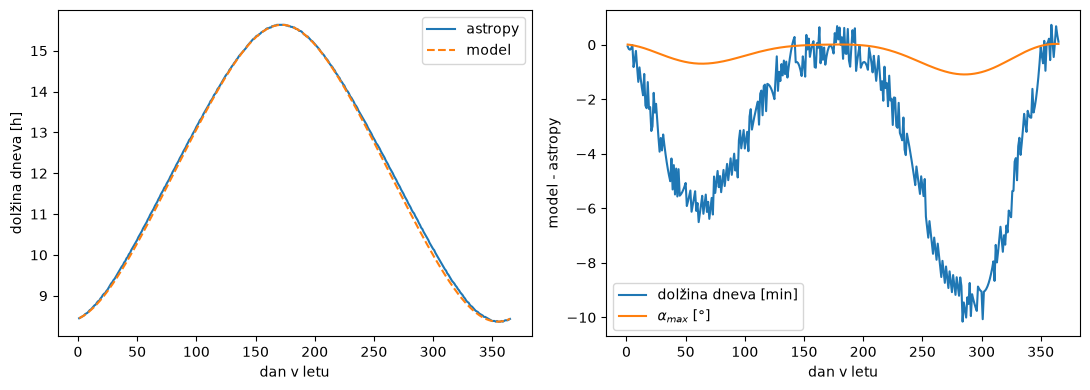

n =   1: dan  8.45 /  8.45 h, alt 20.44 / 20.43°, vzhod  6.79 /  6.80 h UTC
n =  80: dan 11.94 / 12.03 h, alt 43.04 / 43.66°, vzhod  5.12 /  5.08 h UTC
n = 172: dan 15.63 / 15.63 h, alt 66.88 / 66.87°, vzhod  3.17 /  3.18 h UTC
n = 265: dan 11.91 / 12.05 h, alt 42.84 / 43.76°, vzhod  4.86 /  4.82 h UTC
n = 355: dan  8.37 /  8.37 h, alt 20.00 / 20.00°, vzhod  6.76 /  6.75 h UTC


In [4]:
dnevno = pd.read_csv(NAVODILA / "solar_daily.csv", index_col=0)
n_v = np.arange(1, 366)
dan_model = dolzina_dneva(phi, deklinacija(n_v))
alt_model = 90 - phi + deklinacija(n_v)
fig = plt.figure(figsize=(11, 4))
ax = fig.add_subplot(121)
ax.plot(n_v, dnevno["Dolžina dneva"], label="astropy")
ax.plot(n_v, dan_model, "--", label="model")
ax.set_xlabel("dan v letu")
ax.set_ylabel("dolžina dneva [h]")
ax.legend()
ax = fig.add_subplot(122)
ax.plot(n_v, (dan_model - dnevno["Dolžina dneva"]) * 60, label="dolžina dneva [min]")
ax.plot(n_v, alt_model - dnevno["Alt maks"], label=r"$\alpha_{max}$ [°]")
ax.set_xlabel("dan v letu")
ax.set_ylabel("model - astropy")
ax.legend()
fig.tight_layout()
plt.show()
for n in (1, 80, 172, 265, 355):
    r = dnevno.iloc[n - 1]
    print(f"n = {n:3d}: dan {dan_model[n-1]:5.2f} / {r['Dolžina dneva']:5.2f} h, "
          f"alt {alt_model[n-1]:5.2f} / {r['Alt maks']:5.2f}°, vzhod {vzhod_zahod(n)[0]:5.2f} / {r['Sončni vzhod ura']:5.2f} h UTC")

# Naloga 2 - Slika 3

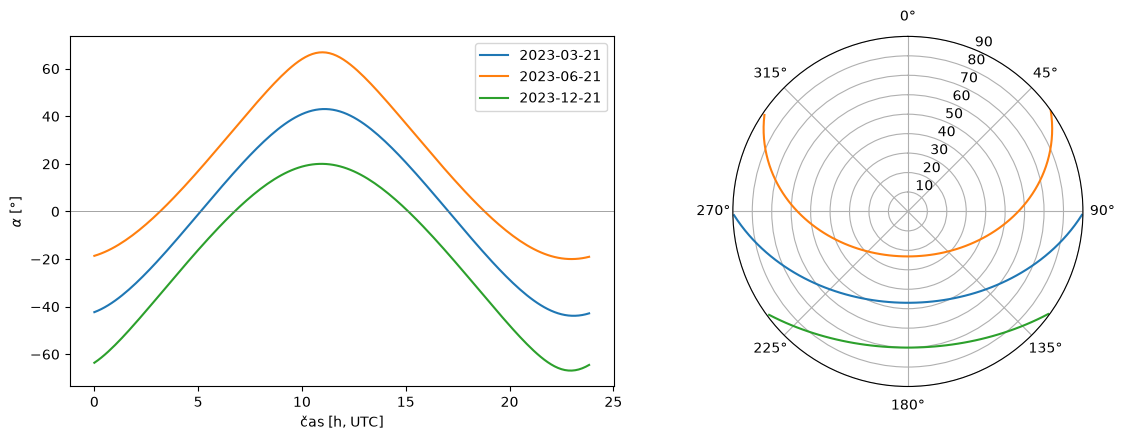

In [5]:
datumi = ["2023-03-21", "2023-06-21", "2023-12-21"]
t = np.arange(0, 24, 1 / 6)
fig = plt.figure(figsize=(12, 4.5))
ax1 = fig.add_subplot(121)
ax2 = fig.add_subplot(122, projection="polar")
for datum in datumi:
    n = dan_v_letu(datum)
    H = urni_kot(t, n)
    a = visina(phi, deklinacija(n), H)
    A = azimut(phi, deklinacija(n), H)
    ax1.plot(t, a, label=datum)
    nad = a > 0
    ax2.plot(d2r(A[nad]), 90 - a[nad], label=datum)
ax1.axhline(0, color="gray", lw=0.5)
ax1.set_xlabel("čas [h, UTC]")
ax1.set_ylabel(r"$\alpha$ [°]")
ax1.legend()
ax2.set_theta_zero_location("N")
ax2.set_theta_direction(-1)
ax2.set_rlim(0, 90)
fig.tight_layout()
plt.show()

# Naloga 3 - Slika 4

2023-03-21: max |d alt| = 0.63°, max |d az| = 0.62°, alt_max astropy = 43.65°
2023-06-21: max |d alt| = 0.05°, max |d az| = 0.16°, alt_max astropy = 66.88°
2023-12-21: max |d alt| = 0.16°, max |d az| = 0.26°, alt_max astropy = 19.99°


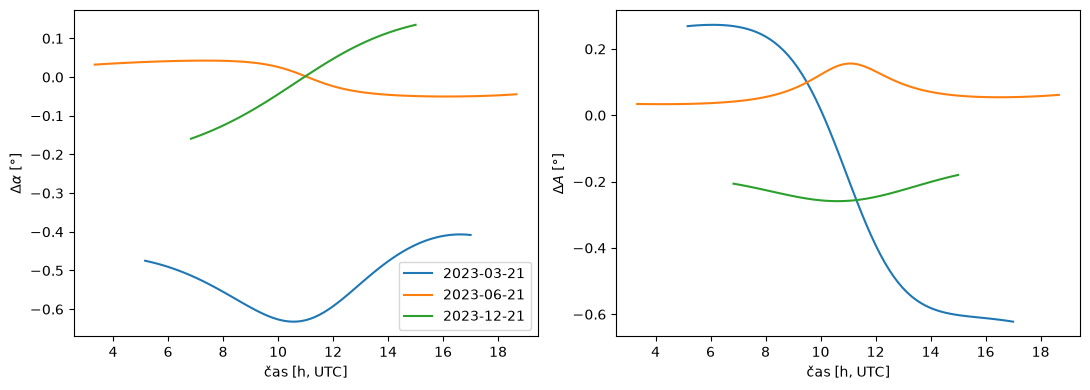

In [6]:
fig = plt.figure(figsize=(11, 4))
ax1 = fig.add_subplot(121)
ax2 = fig.add_subplot(122)
for datum in datumi:
    n = dan_v_letu(datum)
    t_a, alt_a, az_a = astropy_lega(datum)
    H = urni_kot(t_a, n)
    alt_m = visina(phi, deklinacija(n), H)
    az_m = azimut(phi, deklinacija(n), H)
    nad = alt_a > 0
    dA = (az_m - az_a + 180) % 360 - 180
    ax1.plot(t_a[nad], alt_m[nad] - alt_a[nad], label=datum)
    ax2.plot(t_a[nad], dA[nad], label=datum)
    print(f"{datum}: max |d alt| = {np.abs(alt_m - alt_a)[nad].max():.2f}°, "
          f"max |d az| = {np.abs(dA)[nad].max():.2f}°, alt_max astropy = {alt_a.max():.2f}°")
ax1.set_xlabel("čas [h, UTC]")
ax1.set_ylabel(r"$\Delta\alpha$ [°]")
ax2.set_xlabel("čas [h, UTC]")
ax2.set_ylabel(r"$\Delta A$ [°]")
ax1.legend()
fig.tight_layout()
plt.show()

# Naloga 4 - Slika 5

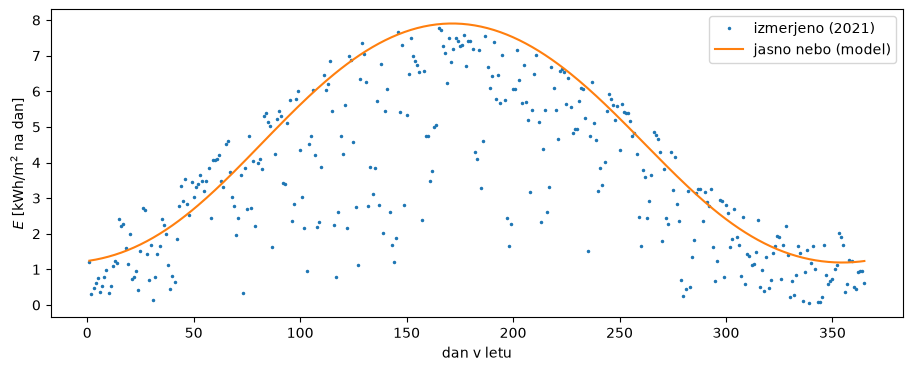

mesec  1: jasno = 1.50, izmerjeno = 1.16 kWh/m^2/dan, indeks jasnosti = 0.77
mesec  3: jasno = 4.11, izmerjeno = 3.73 kWh/m^2/dan, indeks jasnosti = 0.91
mesec  6: jasno = 7.86, izmerjeno = 6.46 kWh/m^2/dan, indeks jasnosti = 0.82
mesec  9: jasno = 4.73, izmerjeno = 4.27 kWh/m^2/dan, indeks jasnosti = 0.90
mesec 12: jasno = 1.23, izmerjeno = 0.92 kWh/m^2/dan, indeks jasnosti = 0.74
letno: jasno = 1640, izmerjeno = 1271 kWh/m^2


In [7]:
vreme = pd.read_csv(NAVODILA / "Vreme_urni.csv")
vreme["cas"] = pd.to_datetime(vreme["date"] + " " + vreme["time"])
tt = np.arange(0, 24, 1 / 6)                       # vsakih 10 minut
E_jasno = np.array([obsevanje_jasno(visina(phi, deklinacija(n), urni_kot(tt, n)), n).sum() / 6 / 1000
                    for n in n_v])
E_mer = vreme.groupby(vreme["cas"].dt.dayofyear)["J"].sum().to_numpy()[:365] / 1000
fig = plt.figure(figsize=(11, 4))
ax = fig.add_subplot(111)
ax.plot(n_v, E_mer, ".", ms=3, label="izmerjeno (2021)")
ax.plot(n_v, E_jasno, label="jasno nebo (model)")
ax.set_xlabel("dan v letu")
ax.set_ylabel(r"$E$ [kWh/m$^2$ na dan]")
ax.legend()
plt.show()
mesec = pd.to_datetime(pd.Series(n_v), unit="D", origin=f"{leto - 1}-12-31").dt.month.to_numpy()
for m in (1, 3, 6, 9, 12):        # Preglednica 4
    print(f"mesec {m:2d}: jasno = {E_jasno[mesec == m].mean():.2f}, izmerjeno = {E_mer[mesec == m].mean():.2f} kWh/m^2/dan, "
          f"indeks jasnosti = {E_mer[mesec == m].mean() / E_jasno[mesec == m].mean():.2f}")
print(f"letno: jasno = {E_jasno.sum():.0f}, izmerjeno = {E_mer.sum():.0f} kWh/m^2")